# 04 · Engenharia de features

Aqui as hipóteses dos passos anteriores viram variáveis. Três princípios guiam todas as decisões:

1. **Disponibilidade no momento da decisão:** só entra o que existe quando o pagamento chega (payload
   da transação + tabelas de referência aprendidas no treino). Informação *point-in-time*.
2. **Paridade treino/produção:** as features ficam em um único módulo,
   [`src/fraude/features.py`](../src/fraude/features.py), usado no treino, na avaliação e na
   inferência online. Isso elimina o risco de reimplementar a lógica de forma diferente na API.
3. **Sem vazamento do alvo:** features calculadas a partir do rótulo (taxa de fraude da categoria e
   score do título) são geradas *out-of-fold* no treino.

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score
from fraude.features import ConstrutorFeatures
from fraude import validacao

In [2]:
base = dados.carregar_base()
tr = base[base["particao"] == "treino"].reset_index(drop=True)
va = base[base["particao"] == "validacao"].reset_index(drop=True)
dev = base[base["particao"] != "teste"].reset_index(drop=True)   # treino + validação
print(f"treino {len(tr):,} | validação {len(va):,} | dev (treino+validação) {len(dev):,}")

treino 76,961 | validação 31,505 | dev (treino+validação) 108,466


## 1. Catálogo de features

In [3]:
cf = ConstrutorFeatures()
X_tr = cf.fit_transform(tr, tr["fraude"])
X_va = cf.transform(va)

catalogo = pd.DataFrame([
    ("a, b, c, d, e, f, h, l, m, n", "payload", "numéricas brutas (nulos preservados)", "sinais de histórico/relacionamento (nb 03)"),
    ("monto", "payload", "valor do pagamento", "risco cresce com o valor"),
    ("o_Y, o_N", "payload", "dummies de o (nulo = ambas 0)", "o tem 3 estados com risco muito distinto"),
    ("p_Y", "payload", "binária", "p = N tem 2,6x o risco"),
    ("pais_*", "payload", "dummies dos países com 500+ transações no treino + pais_nulo", "BR/AR/UY/US têm riscos distintos"),
    ("hora, madrugada, dia_semana", "payload (fecha)", "componentes de data-hora", "fraude ~2,2x maior entre 0h e 5h"),
    ("cat_taxa_fraude", "tabela de referência", "taxa de fraude da categoria j, suavizada (out-of-fold)", "categorias com risco de ~1% a ~27%"),
    ("cat_volume_log", "tabela de referência", "log do nº de transações da categoria no treino", "categorias raras x populares"),
    ("titulo_score", "modelo de texto", "TF-IDF + logística sobre o título i (out-of-fold)", "celulares, gift cards etc."),
], columns=["feature", "origem", "construção", "racional"])
print(f"{X_tr.shape[1]} features:", list(X_tr.columns))
catalogo

25 features: ['a', 'b', 'c', 'd', 'e', 'f', 'h', 'l', 'm', 'n', 'monto', 'o_Y', 'o_N', 'p_Y', 'pais_AR', 'pais_BR', 'pais_US', 'pais_UY', 'pais_nulo', 'hora', 'madrugada', 'dia_semana', 'cat_taxa_fraude', 'cat_volume_log', 'titulo_score']


,feature,origem,construção,racional
0,"a, b, c, d, e, f, h, l, m, n",payload,numéricas brutas (nulos preservados),sinais de histórico/relacionamento (nb 03)
1,monto,payload,valor do pagamento,risco cresce com o valor
2,"o_Y, o_N",payload,dummies de o (nulo = ambas 0),o tem 3 estados com risco muito distinto
3,p_Y,payload,binária,"p = N tem 2,6x o risco"
4,pais_*,payload,dummies dos países com 500+ transações no trei...,BR/AR/UY/US têm riscos distintos
5,"hora, madrugada, dia_semana",payload (fecha),componentes de data-hora,"fraude ~2,2x maior entre 0h e 5h"
6,cat_taxa_fraude,tabela de referência,"taxa de fraude da categoria j, suavizada (out-...",categorias com risco de ~1% a ~27%
7,cat_volume_log,tabela de referência,log do nº de transações da categoria no treino,categorias raras x populares
8,titulo_score,modelo de texto,TF-IDF + logística sobre o título i (out-of-fold),"celulares, gift cards etc."


**Propositalmente fora do modelo:** `k` (ruído), o título e a categoria brutos (entram via
`titulo_score` e `cat_*`) e `score`.

## 2. Avaliação das novas features (ajustadas no treino, medidas na validação)

In [4]:
def auc_univariado(y, x):
    """ROC AUC de uma única variável, independente da direção (0,5 = sem poder)."""
    a = roc_auc_score(y, x)
    return max(a, 1 - a), ("+" if a >= 0.5 else "−")

brutas = ["a", "b", "c", "d", "e", "f", "h", "l", "m", "n", "monto"]
derivadas = [c for c in X_va.columns if c not in brutas]   # todas as colunas criadas pelo construtor
grupo = {c: ("recodificação de o/p" if c.startswith(("o_", "p_")) else
             "recodificação de g (país)" if c.startswith("pais_") else
             "tempo (fecha)" if c in ("hora", "madrugada", "dia_semana") else
             "categoria (j)" if c.startswith("cat_") else "título (i)") for c in derivadas}

linhas = []
for c in derivadas:
    a, d = auc_univariado(va["fraude"], X_va[c])
    binaria = set(X_va[c].dropna().unique()) <= {0, 1}
    linhas.append({"feature": c, "grupo": grupo[c], "ROC AUC (validação)": a, "direção": d,
                   "% com valor 1": X_va[c].mean() if binaria else np.nan})
poder = (pd.DataFrame(linhas).set_index("feature")
           .sort_values(["grupo", "ROC AUC (validação)"], ascending=[True, False]))
print(f"{len(derivadas)} features derivadas avaliadas")
poder.style.format({"ROC AUC (validação)": "{:.3f}", "% com valor 1": "{:.1%}"}, na_rep="—")

14 features derivadas avaliadas


,grupo,ROC AUC (validação),direção,% com valor 1
feature,,,,
cat_taxa_fraude,categoria (j),0.631,+,—
cat_volume_log,categoria (j),0.554,+,—
pais_BR,recodificação de g (país),0.524,+,77.8%
pais_AR,recodificação de g (país),0.513,−,17.6%
pais_UY,recodificação de g (país),0.508,−,2.3%
pais_US,recodificação de g (país),0.503,−,1.4%
pais_nulo,recodificação de g (país),0.500,−,0.2%
o_N,recodificação de o/p,0.709,+,11.8%
p_Y,recodificação de o/p,0.624,−,54.3%


Fazemos uma triagem preliminar com o AUC univariado (o mesmo critério usado para as variáveis brutas no notebook 03), agora sobre **todas as 14 novas features**, separando *recodificações* (mesma informação
do payload em outro formato) de *informação nova* (tempo, categoria, título):

- **Informação nova:** 
  - `titulo_score` (0,64) e `cat_taxa_fraude` (0,63) têm poder individual comparável
  às melhores variáveis brutas;
  - `cat_volume_log` acrescenta um sinal mais fraco (0,55).
- **Tempo:** 
  - `madrugada` (0,53), `hora` (0,51) e `dia_semana` (0,51) parecem fracas, mas o AUC univariado
  só capta relações **monotônicas**. O risco por hora tem formato de "vale" (alto de madrugada, baixo de
  dia), que uma única ordenação não representa, e `madrugada` atinge só ~4% das transações. O valor dessas
  variáveis aparece no modelo multivariado (ablação abaixo).
- **Recodificações:** 
  - `o_N` (0,71) é a coluna derivada mais forte, coerente com a EDA; 
  - `p_Y` (0,62) também é relevante; 
  - `o_Y` (0,52) é fraca sozinha, mas é necessária para separar os três estados de `o`.
- **País:** todas as dummies ficam perto de 0,5. Isso vem em parte da baixa frequência (UY, US e nulo
  somam < 4% das linhas, então o AUC tem pouco espaço para se afastar de 0,5), e em parte do pouco
  poder discriminante do país.

## 3. Ablação com validação cruzada temporal *(pergunta 1)*

Medimos o ganho de cada **grupo** de features com um LightGBM de hiperparâmetros fixos (o algoritmo
ainda não foi escolhido, então é só um instrumento de medida), nos 3 folds temporais definidos a seguir.

Também testamos **`k`**, que não entrou na proposta, para confirmar empiricamente que é ruído.

In [5]:
%%time
folds = validacao.construir_folds(dev)   # features ajustadas só no passado de cada fold
for f in folds:                          # anexa a coluna experimental k
    f.X_tr["k"] = dev.loc[np.arange(len(f.y_tr)), "k"].to_numpy()
    f.X_va["k"] = dev.loc[f.idx_va, "k"].to_numpy()

CPU times: total: 20.7 s
Wall time: 40 s


### Os 3 folds temporais *(pergunta 3)*

A validação cruzada é em **janela expansiva**: cada fold valida em uma semana e treina com **tudo o que
veio antes dela**, sem nunca usar dados do futuro. O teste (11/04–21/04) continua fora de todos os folds.
As features dependentes do alvo (`cat_taxa_fraude`, `titulo_score`) são reajustadas **dentro de cada
fold**, só com o passado daquele fold.

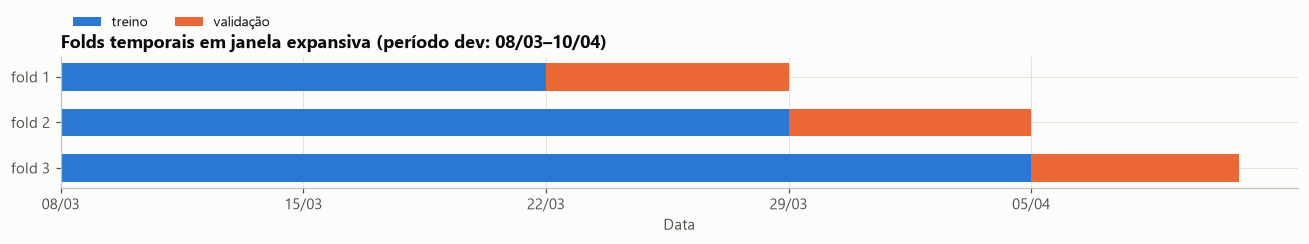

,treino,validação,n treino,n validação,fraudes na validação,taxa de fraude (validação)
fold,,,,,,
1,08/03 – 21/03,22/03 – 28/03,"49,731","20,935",1144,5.46%
2,08/03 – 28/03,29/03 – 04/04,"70,666","16,800",999,5.95%
3,08/03 – 04/04,05/04 – 10/04,"87,466","21,000",1177,5.60%


In [6]:
linhas = []
for f, (inicio, fim) in zip(folds, cfg.FOLDS_TEMPORAIS):
    linhas.append({
        "fold": f.numero,
        "treino": f"{dev['fecha'].min():%d/%m} – {inicio - pd.Timedelta(days=1):%d/%m}",
        "validação": f"{inicio:%d/%m} – {fim - pd.Timedelta(days=1):%d/%m}",
        "n treino": len(f.y_tr), "n validação": len(f.y_va),
        "fraudes na validação": int(f.y_va.sum()), "taxa de fraude (validação)": f.y_va.mean(),
    })
tab_folds = pd.DataFrame(linhas).set_index("fold")

fig, ax = plt.subplots(figsize=(12, 2.4))
ini_dev = dev["fecha"].min().normalize()
for k, (inicio, fim) in enumerate(cfg.FOLDS_TEMPORAIS, start=1):
    ax.barh(k, (inicio - ini_dev).days, left=0, color=gr.AZUL, height=0.6, label="treino" if k == 1 else None)
    ax.barh(k, (fim - inicio).days, left=(inicio - ini_dev).days, color=gr.LARANJA, height=0.6,
            label="validação" if k == 1 else None)
ax.set_yticks([1, 2, 3], [f"fold {k}" for k in [1, 2, 3]])
ax.invert_yaxis()
dias = pd.date_range(ini_dev, cfg.INICIO_TESTE, freq="7D")
ax.set_xticks([(d - ini_dev).days for d in dias], [f"{d:%d/%m}" for d in dias])
ax.set(title="Folds temporais em janela expansiva (período dev: 08/03–10/04)", xlabel="Data")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.12), ncol=2)
plt.tight_layout(); plt.show()
tab_folds.style.format({"taxa de fraude (validação)": "{:.2%}", "n treino": "{:,}", "n validação": "{:,}"})

### Ablação de grupos de features

Agora que definimos os folds temporais, seguimos para a ablação incremental de cada grupo de features.

In [7]:
brutas = ["a", "b", "c", "d", "e", "f", "h", "l", "m", "n", "monto", "o_Y", "o_N", "p_Y"] + \
         [c for c in folds[0].X_tr if c.startswith("pais_")]
tempo = ["hora", "madrugada", "dia_semana"]
categoria = ["cat_taxa_fraude", "cat_volume_log"]
texto = ["titulo_score"]

print(f"Grupo A: originais ({len(brutas)} features) \n" 
      f"Grupo B: originais + tempo ({len(brutas + tempo)} features) \n"
      f"Grupo C: originais + tempo + categoria ({len(brutas + tempo + categoria)} features) \n"
      f"Grupo D: originais + tempo + categoria + texto ({len(brutas + tempo + categoria + texto)} features) \n"
      f"Grupo E: originais + tempo + categoria + texto + k ({len(brutas + tempo + categoria + texto + ['k'])} features) ")

configs = {
    "Grupo A": brutas,
    "Grupo B": brutas + tempo,
    "Grupo C": brutas + tempo + categoria,
    "Grupo D": brutas + tempo + categoria + texto,
    "Grupo E": brutas + tempo + categoria + texto + ["k"],
}
lgbm_fixo = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               random_state=cfg.SEED, verbose=-1)
res = pd.concat([validacao.avaliar_cv(lgbm_fixo, folds, cols, nome)[0] for nome, cols in configs.items()])
ablacao = res.groupby("modelo", sort=False)[["PR AUC", "ROC AUC", "Recall @ FPR 5%"]].mean()
ablacao["Δ PR AUC vs A"] = ablacao["PR AUC"] - ablacao.loc["Grupo A", "PR AUC"]
ablacao

Grupo A: originais (19 features) 
Grupo B: originais + tempo (22 features) 
Grupo C: originais + tempo + categoria (24 features) 
Grupo D: originais + tempo + categoria + texto (25 features) 
Grupo E: originais + tempo + categoria + texto + k (26 features) 


,PR AUC,ROC AUC,Recall @ FPR 5%,Δ PR AUC vs A
modelo,,,,
Grupo A,0.3956,0.8465,0.4574,0.0000
Grupo B,0.4079,0.8503,0.4649,0.0123
Grupo C,0.4146,0.8521,0.4808,0.0189
Grupo D,0.4177,0.8534,0.4807,0.0221
Grupo E,0.4165,0.8530,0.4835,0.0209


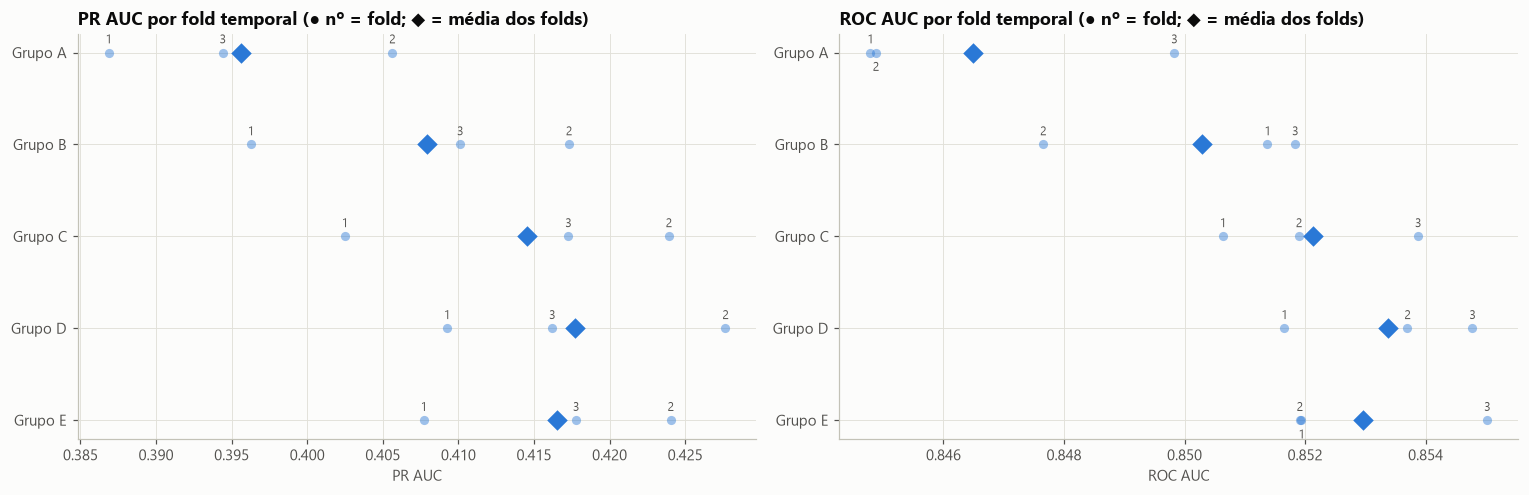

,PR AUC · fold 1,PR AUC · fold 2,PR AUC · fold 3,ROC AUC · fold 1,ROC AUC · fold 2,ROC AUC · fold 3
modelo,,,,,,
Grupo A,0.3869,0.4056,0.3944,0.8448,0.8449,0.8498
Grupo B,0.3963,0.4173,0.4101,0.8514,0.8477,0.8518
Grupo C,0.4025,0.4239,0.4173,0.8506,0.8519,0.8539
Grupo D,0.4092,0.4277,0.4162,0.8517,0.8537,0.8548
Grupo E,0.4077,0.4240,0.4178,0.8519,0.8519,0.8550


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
nomes = list(configs)
for ax, met in zip(axes, ["PR AUC", "ROC AUC"]):
    for i, nome in enumerate(nomes):
        r = res.loc[res["modelo"] == nome]
        v = r[met]
        cor = gr.AZUL
        ax.scatter(v, [i] * len(v), color=cor, s=36, alpha=0.45, zorder=3)
        # número do fold junto de cada ponto; pontos muito próximos alternam acima/abaixo
        perto = 0.02 * (res[met].max() - res[met].min())
        x_ant, acima = None, True
        for x, fold in sorted(zip(v, r["fold"])):
            acima = (not acima) if (x_ant is not None and x - x_ant < perto) else True
            ax.annotate(str(fold), (x, i), xytext=(0, 6 if acima else -12), textcoords="offset points",
                        ha="center", fontsize=8, color=gr.TINTA_2)
            x_ant = x
        ax.scatter(v.mean(), i, color=cor, s=90, marker="D", zorder=4)
    ax.set_yticks(range(len(nomes)), nomes)
    ax.invert_yaxis()
    ax.set(title=f"{met} por fold temporal (● nº = fold; ◆ = média dos folds)", xlabel=met)
plt.tight_layout()
plt.show()

# Valores por fold, para apoiar a leitura do gráfico
por_fold = pd.concat({m: res.pivot(index="modelo", columns="fold", values=m).loc[nomes] for m in ["PR AUC", "ROC AUC"]}, axis=1)
por_fold.columns = [f"{m} · fold {f}" for m, f in por_fold.columns]
por_fold.style.format("{:.4f}")

A variação entre folds (~0,02 de PR AUC) supera a diferença entre as médias dos
grupos **C** a **E** (0,001–0,003), e parte dela vem do próprio período, visto que o fold 2 tem a maior taxa de fraude
(5,95%) e o maior PR AUC em todos os grupos, enquanto o fold 1 tem o menor treino. 

Ainda assim, o ganho de **A** para **D** é sistemático (+0,022 de PR AUC em cada um dos 3 folds). 

Já **E** (`k`) piora as médias.

No ROC AUC, as diferenças são de milésimos. O PR AUC, que mede o topo do ranking, segue como métrica principal.

> Como os folds têm dificuldades diferentes, a comparação mais justa será **pareada**: o ganho de cada
grupo **dentro do mesmo fold**.

In [9]:
def deltas_pareados(met):
    t = res.pivot(index="modelo", columns="fold", values=met).loc[nomes]
    d = pd.DataFrame({
        "Grupo B": t.loc[nomes[1]] - t.loc[nomes[0]],
        "Grupo C": t.loc[nomes[2]] - t.loc[nomes[1]],
        "Grupo D": t.loc[nomes[3]] - t.loc[nomes[2]],
        "Grupo E": t.loc[nomes[4]] - t.loc[nomes[3]],
    }).T
    d.columns = [f"fold {c}" for c in d.columns]
    d["média"] = d.mean(axis=1)
    d["folds com ganho"] = (d.iloc[:, :3] > 0).sum(axis=1).astype(str) + "/3"
    return d

display(deltas_pareados("PR AUC").style.format(precision=4).set_caption("Δ PR AUC por fold"))
display(deltas_pareados("ROC AUC").style.format(precision=4).set_caption("Δ ROC AUC por fold"))

,fold 1,fold 2,fold 3,média,folds com ganho
Grupo B,0.0094,0.0117,0.0157,0.0123,3/3
Grupo C,0.0062,0.0066,0.0072,0.0067,3/3
Grupo D,0.0068,0.0037,-0.0011,0.0031,2/3
Grupo E,-0.0015,-0.0036,0.0016,-0.0012,1/3


,fold 1,fold 2,fold 3,média,folds com ganho
Grupo B,0.0066,0.0028,0.0020,0.0038,3/3
Grupo C,-0.0007,0.0042,0.0020,0.0018,2/3
Grupo D,0.0010,0.0018,0.0009,0.0012,3/3
Grupo E,0.0003,-0.0018,0.0002,-0.0004,2/3


**Leitura:**
- **Grupo B (A + Tempo):** maior ganho incremental (+0,012 de PR AUC), positivo nos 3 folds e nas duas métricas;
- **Grupo C (B + Categoria):** +0,007 de PR AUC, positivo nos 3 folds;
- **Grupo D (C + Texto):** ganho menor (+0,003 PR AUC / +0,001 ROC AUC), positivo em 2 de 3 folds no PR AUC e
  em 3 de 3 no ROC AUC, mas **mantido**;
- **Grupo E (D + `k`):** piora as duas métricas na média, o que **confirma a exclusão**;

> Os ganhos de C e D são pequenos perto da variação entre folds. A decisão de mantê-los se apoia
> também na **direção consistente** e na **plausibilidade de negócio**, e não só na média.

## 4. Conclusão

>O conjunto escolhido é o **Grupo D, com 25 features (listadas abaixo)**. 

Isso se dá porque, do Grupo A (original) até este grupo, cada novo grupo adicionado melhorava ambas métricas ROC AUC e PR AUC. 

Contra o Grupo A, por exemplo, este grupo ganha **+0,022** de PR AUC e **+0,007** de ROC AUC na média dos folds, com ganho em todos os 3 folds. 

Porém, como não há mais ganho ao chegar no Grupo E, paramos no D, incluindo, portanto, **as features mais consistentes e possivelmente seguras para produção.**

> Obs.: Todas essas features vêm do payload da transação ou de tabelas e
modelos ajustados no treino e versionados junto com o modelo, então ficam disponíveis no momento da decisão
sem consulta externa. As duas features que dependem do rótulo são geradas *out-of-fold* no treino, para não
vazar o alvo.   

<details>
<summary>25 features se dividem em seis grupos:</summary>

**Numéricas originais (11).** São usadas como vieram, com os nulos preservados, porque a ausência é
informativa e modelos de árvore lidam com ela nativamente:
- `a`: ordinal de 1 a 4; os níveis 1–3 têm 1,5x a 2x o risco do nível 4.
- `b`: contínua em [0, 1]; risco ~2x maior no decil mais alto e nulo acima da média.
- `c`: contínua e muito assimétrica, nula junto com `b`; sem poder isolado, mas pode contribuir em interações.
- `d`: discreta de 0 a 50; valores baixos e nulos têm mais risco; correlacionada com `m`.
- `e`: razão ≥ 0; valores altos elevam o risco; inversamente relacionada a `monto`.
- `f`: contagem (com códigos negativos); uma das mais fortes, com risco concentrado perto de zero.
- `h`: contagem de 0 a 58; valores baixos com risco um pouco maior.
- `l`: contagem/tempo até ~7,5 mil; uma das mais fortes, com valores baixos indicando pouco histórico.
- `m`: contagem/tempo até ~2,2 mil; mesmo padrão de `l`, e nulo com risco elevado.
- `n`: binária; `n = 0` tem ~3,4x o risco médio.
- `monto`: valor do pagamento; o risco cresce com o valor.

**Recodificações de `o` e `p` (3).** Transformam as variáveis de texto do payload em numéricas:
- `o_Y` e `o_N`: dummies de `o`, com o nulo representado pelas duas em 0. Os três estados têm riscos muito
  distintos (`N` ~4,4x a média, nulo abaixo da metade).
- `p_Y`: binária de `p`; `p = N` tem ~2,6x o risco de `p = Y`.

**País (5).** Só os países com volume suficiente ganham coluna própria:
- `pais_AR`, `pais_BR`, `pais_US` e `pais_UY`: dummies dos países com 500+ transações no treino; os demais
  ficam todos em 0. BR fica acima da média, AR e US abaixo, UY bem abaixo.
- `pais_nulo`: indicador de país ausente, que preserva a ausência como informação.

**Tempo (3).** Derivadas do horário da transação (`fecha`):
- `hora`: de 0 a 23; o risco tem formato de "vale", com pico de madrugada.
- `madrugada`: indicador de 0h a 5h, horário com fraude ~2,2x maior.
- `dia_semana`: de 0 (segunda) a 6 (domingo); efeito fraco, mas parte do ganho conjunto do grupo.

**Categoria do produto (2).** Resumem a categoria `j`, que tem 8,3 mil valores:
- `cat_taxa_fraude`: taxa de fraude da categoria, suavizada para a média global e gerada *out-of-fold*. As
  categorias vão de ~1% a ~27% de fraude.
- `cat_volume_log`: log do nº de transações da categoria no treino; separa categorias raras de populares.

**Título do produto (1).**
- `titulo_score`: TF-IDF (palavras e bigramas) + regressão logística sobre o título `i`, gerado
  *out-of-fold*. Resume o risco de produtos visados, como celulares, gift cards e itens de revenda.

**E algumas variáveis ficaram propositalmente de fora:**
- `k`: um valor por linha, distribuição uniforme e sem relação com o alvo. Na ablação, só piorou as métricas.
- `i`, `j` e `fecha` brutos: entram de forma resumida, via `titulo_score`, `cat_*` e as features de tempo.
- `score` do modelo atual: deixado de fora para que o novo modelo seja independente e possa substituí-lo.

</details>